# Focal optimization with a spatial phase map

A 9×9 phase-only aperture is optimized to raise |Ex|² at an off-axis focal point. The trainable parameter is a real phase value at each aperture sample, so autograd produces a spatial d|Ex|²/dφ map. Fields and geometry start in float64/complex128, then the explicit surface copy uses CPU or CUDA precision for optimization. A deterministic directional finite-difference check sweeps epsilon.

The aperture field relation Ex × Hy points along +z. |Ex|² is an intensity proxy, not flux in W/m². This checks differentiation through the fixed-geometry exact focal projector for a constructed field; it does not claim a full-wave material-permittivity adjoint gradient.


In [ ]:
from pathlib import Path
import sys

ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "core" / "nearfield").is_dir()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Could not locate repository root containing core/nearfield")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples/nearfield"))
import time, numpy as np, torch, matplotlib.pyplot as plt
from IPython.display import display
from core.nearfield import Surface, project_nearfield
from notebook_utils import (
    field_components,
    surface_copy,
    benchmark_methods,
    show_benchmarks,
    show_errors,
    show_errors,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RD = torch.float64
CD = torch.complex128
OD = torch.float32 if DEVICE.type == "cuda" else torch.float64
OC = torch.complex64 if DEVICE.type == "cuda" else torch.complex128
freq = 193.4e12
wavelength = 299792458.0 / freq
n = 9
length = 2e-6
delta = length / n
axis = (torch.arange(n, dtype=RD) + 0.5) * delta - length / 2
y, x = torch.meshgrid(axis, axis, indexing="ij")
pos = torch.stack((x, y, torch.zeros_like(x)), dim=-1).reshape(-1, 3)
norm = torch.zeros_like(pos)
norm[:, 2] = 1
weights = torch.full((n * n,), delta**2, dtype=RD)
amp = torch.exp(-((x / 0.8e-6) ** 2 + (y / 0.8e-6) ** 2))
ev = torch.zeros((1, n * n, 3), dtype=CD)
hv = torch.zeros_like(ev)
ev[0, :, 0] = amp.reshape(-1).to(CD)
hv[0, :, 1] = ev[0, :, 0] / 376.730313668
surface_ref = Surface(pos, norm, weights, ev, hv, torch.tensor([freq], dtype=RD))
surface = surface_copy(surface_ref, device=DEVICE, dtype=OC)
target = torch.tensor([[0.34e-6, -0.22e-6, 2.8 * wavelength]], device=DEVICE, dtype=OD)
base = amp.to(device=DEVICE, dtype=OD).reshape(-1)
print(
    f"device={DEVICE}; aperture={n}×{n}; target=({target[0,0]*1e6:.3f}, {target[0,1]*1e6:.3f}, {target[0,2]*1e6:.3f}) µm"
)

device=cuda; aperture=9×9; target=(0.340, -0.220, 4.340) µm


In [ ]:
phase = torch.nn.Parameter(torch.zeros((n, n), device=DEVICE, dtype=OD))
optimizer = torch.optim.Adam([phase], lr=0.16)


def make_surface(phi):
    """Apply a phase-only map while preserving the real aperture amplitude."""
    ex = base.to(OC) * torch.exp(1j * phi.reshape(-1)).to(OC)
    efield = torch.zeros((1, n * n, 3), device=DEVICE, dtype=OC)
    hfield = torch.zeros_like(efield)
    efield[0, :, 0] = ex
    hfield[0, :, 1] = ex / 376.730313668
    return Surface(
        surface.positions_m,
        surface.normals,
        surface.weights_m2,
        efield,
        hfield,
        surface.frequencies_hz,
    )


def focus(phi):
    """Return focal |Ex|² for fixed geometry and frequency."""
    field, _ = project_nearfield(
        make_surface(phi), target, source_chunk_size=128, observation_chunk_size=1
    )
    return field[0, 0, 0].abs().square()


history = []
grad_norm = []
for _ in range(20):
    optimizer.zero_grad(set_to_none=True)
    loss = -focus(phase)
    loss.backward()
    grad_norm.append(float(torch.linalg.vector_norm(phase.grad).detach()))
    optimizer.step()
    history.append(float((-loss).detach()))
phase_after = phase.detach().clone()
phase_before = torch.zeros_like(phase_after)
print(f"Focal |Ex|²: {history[0]:.6g} -> {float(focus(phase_after).detach()):.6g}")

Focal |Ex|²: 0.0582745 -> 0.0612407


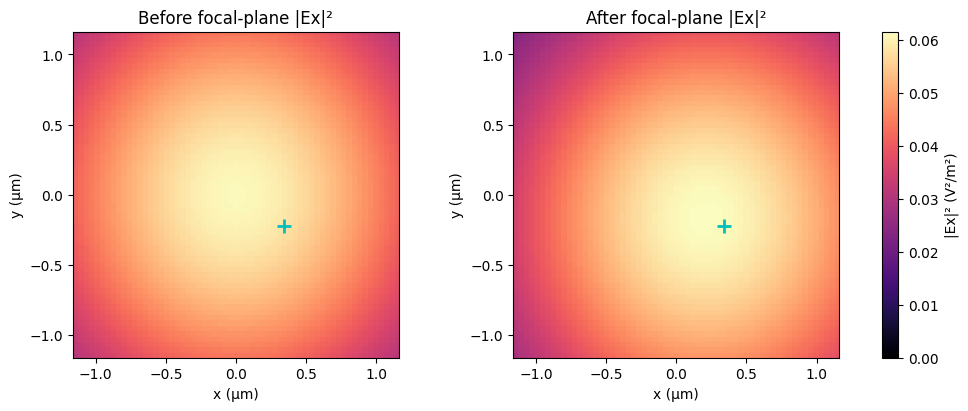

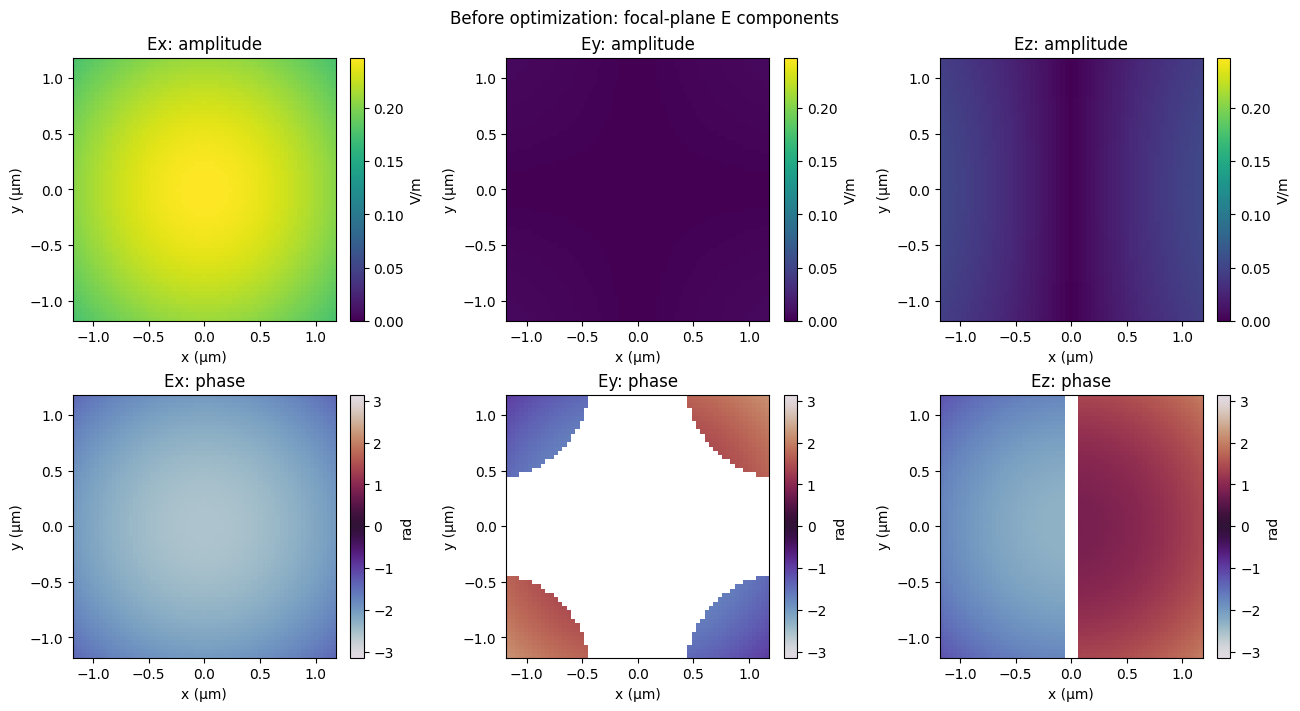

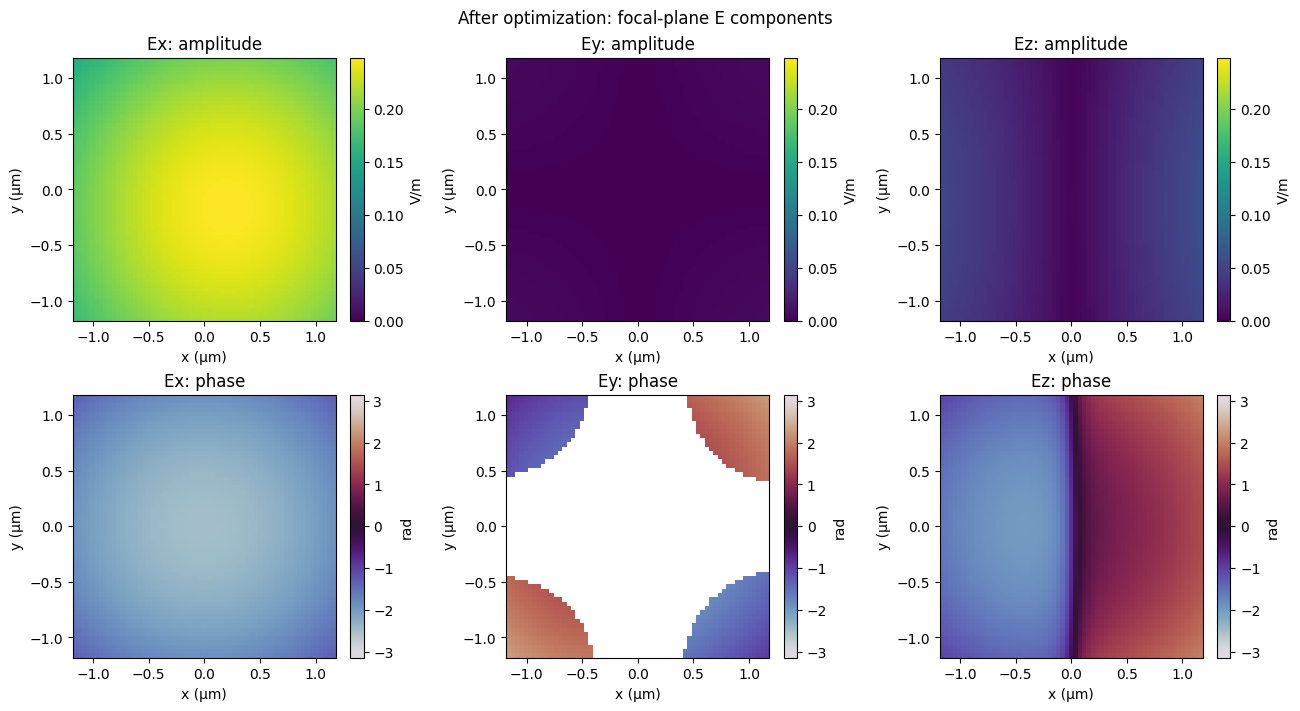

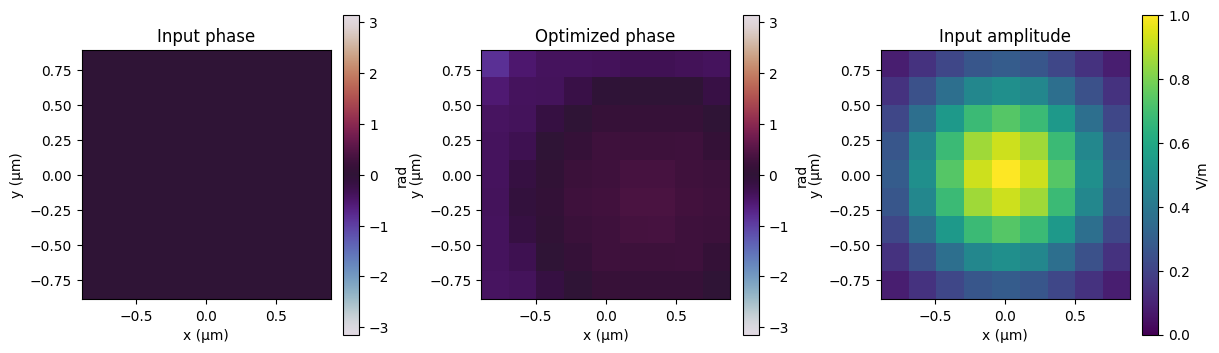

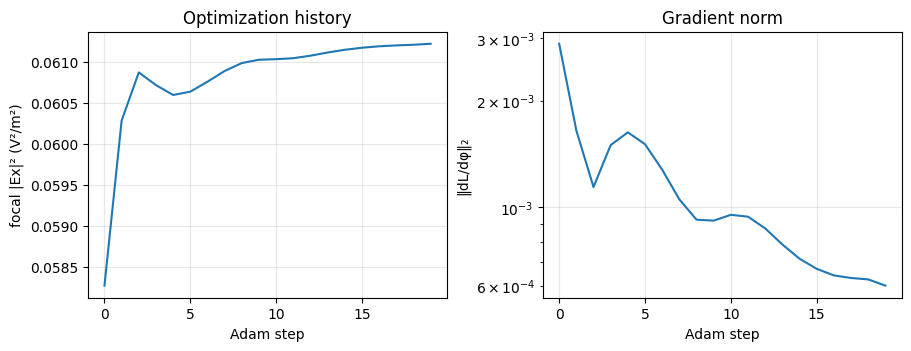

In [ ]:
# Same plane and color scale make the before/after field views comparable.
with torch.no_grad():
    span = torch.linspace(
        -0.75 * wavelength, 0.75 * wavelength, 61, device=DEVICE, dtype=OD
    )
    yy, xx = torch.meshgrid(span, span, indexing="ij")
    obs = torch.stack((xx, yy, torch.full_like(xx, target[0, 2])), dim=-1).reshape(
        -1, 3
    )
    before, _ = project_nearfield(
        make_surface(phase_before),
        obs,
        source_chunk_size=128,
        observation_chunk_size=512,
    )
    after, _ = project_nearfield(
        make_surface(phase_after),
        obs,
        source_chunk_size=128,
        observation_chunk_size=512,
    )
    before = before[0].reshape(61, 61, 3).cpu().numpy()
    after = after[0].reshape(61, 61, 3).cpu().numpy()
    ib = np.abs(before[..., 0]) ** 2
    ia = np.abs(after[..., 0]) ** 2
    vmax = max(ib.max(), ia.max())
    fig, axs = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    for ax, data, title in zip(axs, (ib, ia), ("Before", "After")):
        im = ax.imshow(
            data,
            origin="lower",
            extent=[span[0].item() * 1e6, span[-1].item() * 1e6] * 2,
            vmin=0,
            vmax=vmax,
            cmap="magma",
        )
        ax.plot(
            target[0, 0].item() * 1e6, target[0, 1].item() * 1e6, "c+", ms=10, mew=2
        )
        ax.set(title=title + " focal-plane |Ex|²", xlabel="x (µm)", ylabel="y (µm)")
    fig.colorbar(im, ax=axs, label="|Ex|² (V²/m²)")
    plt.show()
    _ = field_components(
        before,
        span.cpu().numpy() * 1e6,
        span.cpu().numpy() * 1e6,
        title="Before optimization: focal-plane E components",
        quantity="E",
        units="V/m",
    )
    _ = field_components(
        after,
        span.cpu().numpy() * 1e6,
        span.cpu().numpy() * 1e6,
        title="After optimization: focal-plane E components",
        quantity="E",
        units="V/m",
    )
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, data, title, cmap in zip(
    axs,
    (phase_before.cpu().numpy(), phase_after.cpu().numpy(), amp.numpy()),
    ("Input phase", "Optimized phase", "Input amplitude"),
    ("twilight", "twilight", "viridis"),
):
    im = ax.imshow(
        data,
        origin="lower",
        extent=[axis[0] * 1e6, axis[-1] * 1e6] * 2,
        cmap=cmap,
        vmin=-np.pi if cmap == "twilight" else 0,
        vmax=np.pi if cmap == "twilight" else float(amp.max()),
    )
    ax.set(title=title, xlabel="x (µm)", ylabel="y (µm)")
    fig.colorbar(im, ax=ax, label="rad" if cmap == "twilight" else "V/m")
plt.show()
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), constrained_layout=True)
axs[0].plot(history)
axs[0].set(
    xlabel="Adam step", ylabel="focal |Ex|² (V²/m²)", title="Optimization history"
)
axs[0].grid(True, alpha=0.3)
axs[1].semilogy(np.maximum(grad_norm, 1e-30))
axs[1].set(xlabel="Adam step", ylabel="‖dL/dφ‖₂", title="Gradient norm")
axs[1].grid(True, alpha=0.3)
plt.show()

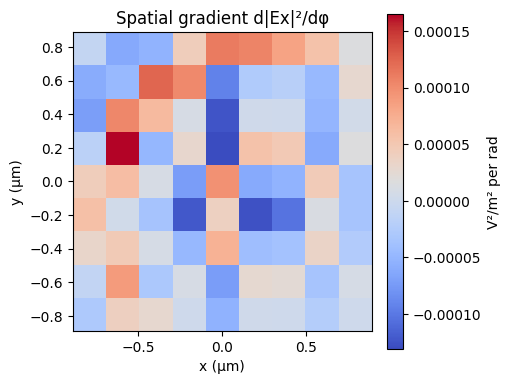

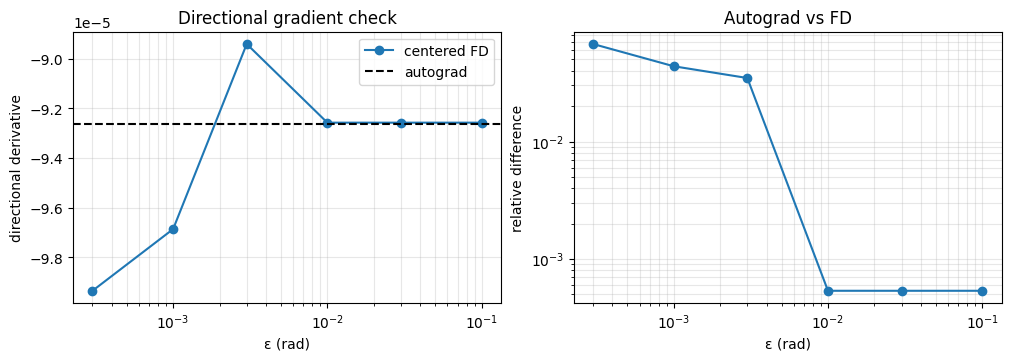

(epsilon, centered FD, relative difference): [(0.1, -9.257346391677856e-05, 0.0005362125812098384), (0.03, -9.257347119273618e-05, 0.0005361340008676052), (0.01, -9.257346391677856e-05, 0.0005362125812098384), (0.003, -8.940696716308594e-05, 0.034723103046417236), (0.001, -9.685754048405215e-05, 0.04371792823076248), (0.0003, -9.934107220033184e-05, 0.0676250234246254)]


In [ ]:
# Spatial derivative map and finite-difference directional check.
phi = phase_after.clone().requires_grad_(True)
val = focus(phi)
grad = torch.autograd.grad(val, phi)[0]
fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
im = ax.imshow(
    grad.detach().cpu().numpy(),
    origin="lower",
    extent=[axis[0] * 1e6, axis[-1] * 1e6] * 2,
    cmap="coolwarm",
)
ax.set(title="Spatial gradient d|Ex|²/dφ", xlabel="x (µm)", ylabel="y (µm)")
fig.colorbar(im, ax=ax, label="V²/m² per rad")
plt.show()
gen = torch.Generator(device=DEVICE).manual_seed(7)
direction = torch.randn((n, n), generator=gen, device=DEVICE, dtype=OD)
direction /= torch.linalg.vector_norm(direction)
auto = (grad * direction).sum().detach()
rows = []
for eps in (1e-1, 3e-2, 1e-2, 3e-3, 1e-3, 3e-4):
    with torch.no_grad():
        fd = (
            focus(phase_after + eps * direction) - focus(phase_after - eps * direction)
        ) / (2 * eps)
    rel = (fd - auto).abs() / torch.maximum(fd.abs(), auto.abs()).clamp_min(1e-12)
    rows.append((eps, float(fd), float(rel)))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axs[0].semilogx([r[0] for r in rows], [r[1] for r in rows], "o-", label="centered FD")
axs[0].axhline(float(auto), color="k", ls="--", label="autograd")
axs[0].set(
    xlabel="ε (rad)",
    ylabel="directional derivative",
    title="Directional gradient check",
)
axs[0].grid(True, which="both", alpha=0.3)
axs[0].legend()
axs[1].loglog([r[0] for r in rows], [r[2] for r in rows], "o-")
axs[1].set(xlabel="ε (rad)", ylabel="relative difference", title="Autograd vs FD")
axs[1].grid(True, which="both", alpha=0.3)
plt.show()
print("(epsilon, centered FD, relative difference):", rows)

## Optional backend profile

The benchmark separates forward projection and gradient work for the same fixed-geometry case. Warm timings include cached work; the helper reports first-observed and warm timings, synchronizes CUDA, and reports peak allocated memory where CUDA is available. These small-case results are measurements for this device and precision, not broad performance claims.

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
E: Torch c64 vs Triton c64,1.758e-07,7.695e-09,2.3283e-07,1.758e-07,N/A,1,0
H: Torch c64 vs Triton c64,2.4725e-07,0,5.9599e-07,2.4725e-07,N/A,1,0


method,device,dtype,output_shape,first_forward_ms,warm_forward_ms,first_gradient_forward_ms,first_backward_ms,warm_backward_ms,warm_forward_backward_ms,peak_allocated_mib,peak_increment_mib,warmups,repeats
Exact Torch c64,cuda,torch.complex64,"(1, 1, 3)",19.27,20.142,17.797,4.8211,4.8132,23.578,0.11182,0.036133,1,3
Exact Triton c64,cuda,torch.complex64,"(1, 1, 3)",16.294,20.749,22.744,38.908,36.481,56.413,0.11328,0.037598,1,3


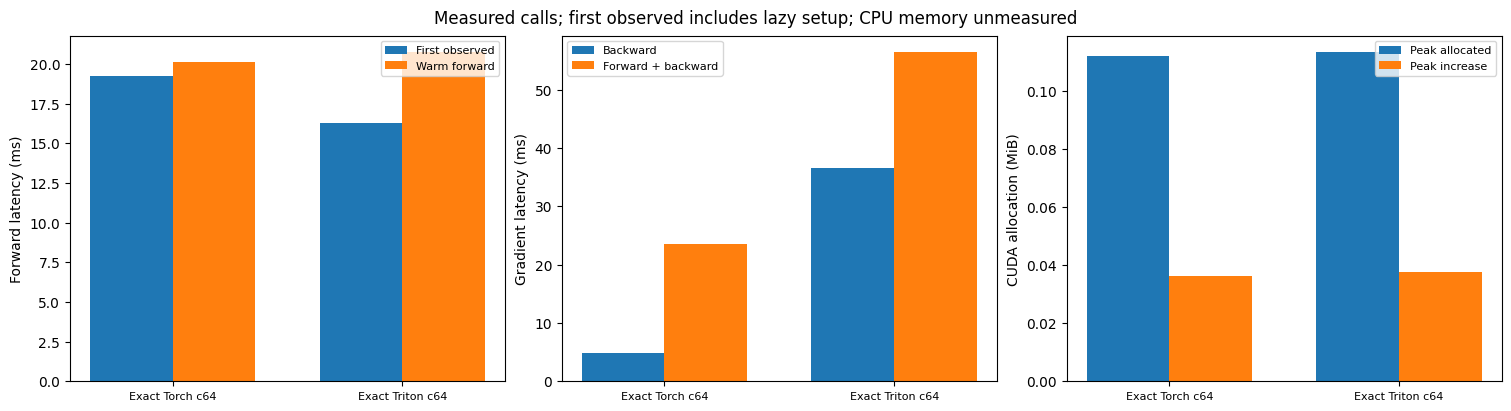

In [ ]:
if DEVICE.type == "cuda":
    try:
        from core.nearfield.triton_backend import project_nearfield_triton

        profile_surface = surface_copy(
            surface_ref, device=DEVICE, dtype=torch.complex64, requires_grad=True
        )
        target32 = target.to(dtype=torch.float32)
        torch_outputs = project_nearfield(profile_surface, target32)
        triton_outputs = project_nearfield_triton(profile_surface, target32)
        from notebook_utils import error_summary

        show_errors(
            [
                error_summary(
                    torch_outputs[0],
                    triton_outputs[0],
                    label="E: Torch c64 vs Triton c64",
                ),
                error_summary(
                    torch_outputs[1],
                    triton_outputs[1],
                    label="H: Torch c64 vs Triton c64",
                ),
            ]
        )
        records = benchmark_methods(
            {
                "Exact Torch c64": lambda: project_nearfield(profile_surface, target32),
                "Exact Triton c64": lambda: project_nearfield_triton(
                    profile_surface, target32
                ),
            },
            device=DEVICE,
            backward_inputs=(
                profile_surface.electric_fields,
                profile_surface.magnetic_fields,
            ),
            warmups=1,
            repeats=3,
        )
        show_benchmarks(records)
    except (ImportError, RuntimeError, NotImplementedError) as exc:
        print(f"Triton GPU profile unavailable: {type(exc).__name__}: {exc}")
else:
    profile_surface = surface_copy(
        surface_ref, device=DEVICE, dtype=OC, requires_grad=True
    )
    profile_forward = lambda: project_nearfield(
        profile_surface, target, source_chunk_size=128, observation_chunk_size=1
    )
    records = benchmark_methods(
        {"Exact Torch CPU": profile_forward},
        device=DEVICE,
        backward_inputs=(
            profile_surface.electric_fields,
            profile_surface.magnetic_fields,
        ),
        warmups=1,
        repeats=3,
    )
    show_benchmarks(records)

## Pixel gradients, backend agreement, and precision

Finite differences below expose the complex64 cancellation floor as epsilon shrinks. Backend comparisons use identical fields and targets; precision comparisons retain the same optimized phase.

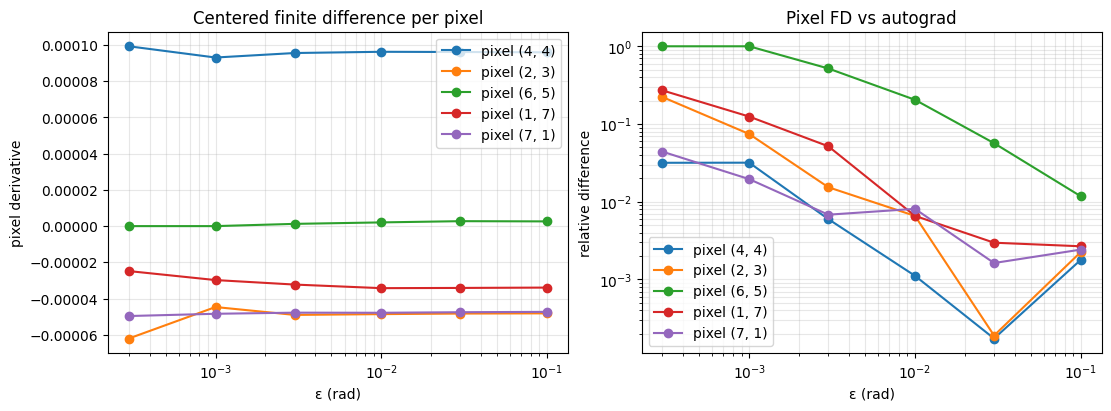

Pixel [row,col], autograd derivative, (epsilon, centered FD, relative difference):
((4, 4), 9.619131742510945e-05, [(0.1, 9.601935744285583e-05, 0.001787687186151743), (0.03, 9.617458272259682e-05, 0.00017397310875821859), (0.01, 9.629875421524048e-05, 0.0011156612308695912), (0.003, 9.561578917782754e-05, 0.005983162205666304), (0.001, 9.313225018559024e-05, 0.03180190548300743), (0.0003, 9.934107220033184e-05, 0.031706470996141434)])
((2, 3), -4.829542012885213e-05, [(0.1, -4.818663001060486e-05, 0.0022525968961417675), (0.03, -4.830460238736123e-05, 0.0001900907518574968), (0.01, -4.861503839492798e-05, 0.0065744733437895775), (0.003, -4.9049656809074804e-05, 0.015377001836895943), (0.001, -4.470347994356416e-05, 0.07437434047460556), (0.0003, -6.20881692157127e-05, 0.22214777767658234)])
((6, 5), 2.5770364118216094e-06, [(0.1, 2.60770320892334e-06, 0.011760079301893711), (0.03, 2.731879703787854e-06, 0.05668012797832489), (0.01, 2.0489096641540527e-06, 0.2049356997013092), (0.003, 

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
E field: Torch c64 vs Triton c64,1.758e-07,7.695e-09,2.3283e-07,1.758e-07,N/A,1,0
H field: Torch c64 vs Triton c64,2.4725e-07,0,5.9599e-07,2.4725e-07,N/A,1,0
dL/dE: Torch vs Triton c64,1.818e-07,7.365e-08,2.2347e-07,1.818e-07,N/A,81,0
dL/dH: Torch vs Triton c64,1.91e-07,9.8919e-08,1.887e-07,1.91e-07,N/A,81,0


label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
focal E field: c64 vs c128,1.3887e-06,2.7197e-08,1.373e-06,1.3887e-06,N/A,1,0
focal H field: c64 vs c128,1.3233e-06,3.7634e-08,1.1919e-06,1.3233e-06,N/A,1,0


{'focal_intensity_c64': 0.06124068796634674, 'focal_intensity_c128': 0.0612406992866451, 'relative_gradient_l2_c64_vs_c128': 2.4522543851017447e-05, 'gradient_max_abs_error_over_c128_peak': 2.6142533497064747e-05}


In [ ]:
# Pixelwise finite differences on a subset of phase parameters.
# This complements the whole-map directional derivative epsilon sweep above.
phi_check = phase_after.clone().requires_grad_(True)
loss_check = focus(phi_check)
grad_check = torch.autograd.grad(loss_check, phi_check)[0].detach()
pixels = ((4, 4), (2, 3), (6, 5), (1, 7), (7, 1))
epsilons = (1e-1, 3e-2, 1e-2, 3e-3, 1e-3, 3e-4)
pixel_rows = []
for ij in pixels:
    estimates = []
    for eps in epsilons:
        perturb = torch.zeros_like(phase_after)
        perturb[ij] = eps
        with torch.no_grad():
            fd = (focus(phase_after + perturb) - focus(phase_after - perturb)) / (
                2 * eps
            )
        auto = grad_check[ij]
        rel = (fd - auto).abs() / torch.maximum(fd.abs(), auto.abs()).clamp_min(1e-12)
        estimates.append((eps, float(fd), float(rel)))
    pixel_rows.append((ij, float(grad_check[ij]), estimates))
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ij, auto, estimates in pixel_rows:
    axs[0].semilogx(
        [r[0] for r in estimates], [r[1] for r in estimates], "o-", label=f"pixel {ij}"
    )
    axs[1].loglog(
        [r[0] for r in estimates],
        [max(r[2], 1e-16) for r in estimates],
        "o-",
        label=f"pixel {ij}",
    )
axs[0].set(
    xlabel="ε (rad)",
    ylabel="pixel derivative",
    title="Centered finite difference per pixel",
)
axs[0].grid(True, which="both", alpha=0.3)
axs[0].legend()
axs[1].set(xlabel="ε (rad)", ylabel="relative difference", title="Pixel FD vs autograd")
axs[1].grid(True, which="both", alpha=0.3)
axs[1].legend()
plt.show()
print(
    "Pixel [row,col], autograd derivative, (epsilon, centered FD, relative difference):"
)
for row in pixel_rows:
    print(row)

# Compare field and gradient outputs for exactly the same c64 surface and target.
if DEVICE.type == "cuda":
    from core.nearfield.triton_backend import project_nearfield_triton

    compare_surface = surface_copy(
        surface_ref, device=DEVICE, dtype=torch.complex64, requires_grad=True
    )
    compare_target = target.to(device=DEVICE, dtype=torch.float32)
    torch_e, torch_h = project_nearfield(compare_surface, compare_target)
    triton_e, triton_h = project_nearfield_triton(compare_surface, compare_target)

    def output_energy(e, h):
        return e.abs().square().sum() + h.abs().square().sum()

    torch_ge, torch_gh = torch.autograd.grad(
        output_energy(torch_e, torch_h),
        (compare_surface.electric_fields, compare_surface.magnetic_fields),
    )
    triton_ge, triton_gh = torch.autograd.grad(
        output_energy(triton_e, triton_h),
        (compare_surface.electric_fields, compare_surface.magnetic_fields),
    )
    show_errors(
        [
            error_summary(torch_e, triton_e, label="E field: Torch c64 vs Triton c64"),
            error_summary(torch_h, triton_h, label="H field: Torch c64 vs Triton c64"),
            error_summary(torch_ge, triton_ge, label="dL/dE: Torch vs Triton c64"),
            error_summary(torch_gh, triton_gh, label="dL/dH: Torch vs Triton c64"),
        ]
    )
else:
    print("Torch/Triton field and gradient comparison skipped: CUDA is unavailable.")


# Compare the optimized phase point at complex64 and complex128 on the same device.
# The optimization above uses complex64 on CUDA; this reports its precision error
# against the float64/complex128 reference without relabeling a higher-precision
# trajectory as the optimization actually performed.
from notebook_utils import error_summary, show_errors, surface_copy


def precision_focal(real_dtype, complex_dtype):
    srf = surface_copy(surface_ref, device=DEVICE, dtype=complex_dtype)
    phi = phase_after.to(device=DEVICE, dtype=real_dtype).detach().requires_grad_(True)
    a = amp.to(device=DEVICE, dtype=real_dtype).reshape(-1).to(complex_dtype)
    ex = a * torch.exp(1j * phi.reshape(-1)).to(complex_dtype)
    ev = torch.zeros((1, n * n, 3), device=DEVICE, dtype=complex_dtype)
    hv = torch.zeros_like(ev)
    ev[0, :, 0] = ex
    hv[0, :, 1] = ex / 376.730313668
    srf = Surface(
        srf.positions_m, srf.normals, srf.weights_m2, ev, hv, srf.frequencies_hz
    )
    targ = target.to(device=DEVICE, dtype=real_dtype)
    ee, hh = project_nearfield(
        srf, targ, source_chunk_size=128, observation_chunk_size=1
    )
    focal = ee[0, 0, 0].abs().square()
    gp = torch.autograd.grad(focal, phi)[0]
    return ee.detach(), hh.detach(), focal.detach(), gp.detach()


if DEVICE.type == "cuda":
    e64, h64, i64, g64 = precision_focal(torch.float32, torch.complex64)
    e128, h128, i128, g128 = precision_focal(torch.float64, torch.complex128)
    show_errors(
        [
            error_summary(e128, e64, label="focal E field: c64 vs c128"),
            error_summary(h128, h64, label="focal H field: c64 vs c128"),
        ]
    )
    gden = torch.linalg.vector_norm(g128).clamp_min(torch.finfo(g128.dtype).tiny)
    print(
        {
            "focal_intensity_c64": float(i64),
            "focal_intensity_c128": float(i128),
            "relative_gradient_l2_c64_vs_c128": float(
                torch.linalg.vector_norm(g64 - g128) / gden
            ),
            "gradient_max_abs_error_over_c128_peak": float(
                (g64 - g128).abs().max()
                / g128.abs().max().clamp_min(torch.finfo(g128.dtype).tiny)
            ),
        }
    )
else:
    print(
        "Precision comparison: CPU optimization already used float64/complex128; no lower-precision optimization was run."
    )

## Resolve finite-difference cancellation with complex128

Small differences of complex64 intensities can lose accuracy for weak derivatives. Repeat the same optimized phase and objective in complex128; both directional and individual-pixel checks must pass the 1% target for at least one tested step size.

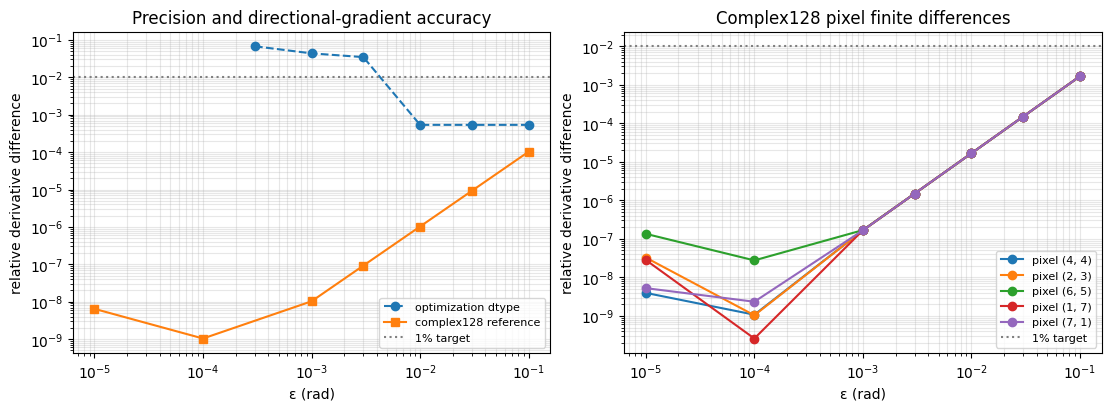

Best complex128 directional error: 1.0398616194604993e-09
Best complex128 pixel errors: {(4, 4): 1.0754414145002404e-09, (2, 3): 1.0383645834003183e-09, (6, 5): 2.7636073277506446e-08, (1, 7): 2.591060309966445e-10, (7, 1): 2.3360628342662935e-09}


In [ ]:
# Double precision resolves the cancellation floor exposed by complex64 checks.
reference_surface = surface_copy(surface_ref, device=DEVICE, dtype=torch.complex128)
reference_target = target.to(torch.float64)
reference_amplitude = amp.to(device=DEVICE, dtype=torch.float64).reshape(-1)


def focus_reference(phi):
    """Evaluate the same focal objective in complex128 at a supplied phase map."""
    ex = reference_amplitude * torch.exp(1j * phi.reshape(-1))
    electric = torch.zeros((1, n * n, 3), device=DEVICE, dtype=torch.complex128)
    magnetic = torch.zeros_like(electric)
    electric[0, :, 0] = ex
    magnetic[0, :, 1] = ex / 376.730313668
    near = Surface(
        reference_surface.positions_m,
        reference_surface.normals,
        reference_surface.weights_m2,
        electric,
        magnetic,
        reference_surface.frequencies_hz,
    )
    ef, _ = project_nearfield(near, reference_target)
    return ef[0, 0, 0].abs().square()


reference_phase = phase_after.to(torch.float64).detach().requires_grad_(True)
reference_gradient = torch.autograd.grad(
    focus_reference(reference_phase), reference_phase
)[0]
reference_direction = direction.to(torch.float64)
reference_auto = (reference_gradient * reference_direction).sum().detach()
double_eps = (1e-1, 3e-2, 1e-2, 3e-3, 1e-3, 1e-4, 1e-5)
directional_errors = []
pixel_errors = {pixel: [] for pixel in pixels}
with torch.no_grad():
    for epsilon in double_eps:
        finite = (
            focus_reference(reference_phase + epsilon * reference_direction)
            - focus_reference(reference_phase - epsilon * reference_direction)
        ) / (2 * epsilon)
        directional_errors.append(
            float(
                (finite - reference_auto).abs()
                / torch.maximum(finite.abs(), reference_auto.abs()).clamp_min(1e-15)
            )
        )
        for pixel in pixels:
            perturb = torch.zeros_like(reference_phase)
            perturb[pixel] = epsilon
            finite = (
                focus_reference(reference_phase + perturb)
                - focus_reference(reference_phase - perturb)
            ) / (2 * epsilon)
            automatic = reference_gradient[pixel]
            pixel_errors[pixel].append(
                float(
                    (finite - automatic).abs()
                    / torch.maximum(finite.abs(), automatic.abs()).clamp_min(1e-15)
                )
            )
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axs[0].loglog(
    [row[0] for row in rows],
    [row[2] for row in rows],
    "o--",
    label="optimization dtype",
)
axs[0].loglog(double_eps, directional_errors, "s-", label="complex128 reference")
axs[0].set(
    xlabel="ε (rad)",
    ylabel="relative derivative difference",
    title="Precision and directional-gradient accuracy",
)
for pixel, errors in pixel_errors.items():
    axs[1].loglog(double_eps, errors, "o-", label=f"pixel {pixel}")
axs[1].set(
    xlabel="ε (rad)",
    ylabel="relative derivative difference",
    title="Complex128 pixel finite differences",
)
for ax in axs:
    ax.axhline(0.01, color="gray", ls=":", label="1% target")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
plt.show()
print("Best complex128 directional error:", min(directional_errors))
print(
    "Best complex128 pixel errors:",
    {pixel: min(errors) for pixel, errors in pixel_errors.items()},
)
assert min(directional_errors) < 0.01
assert all(min(errors) < 0.01 for errors in pixel_errors.values())